# Продажи VINTAGE SNAP CARDS

В этой работе я проверяю, можно ли использовать журнал продаж товара **VINTAGE SNAP CARDS (21790)** для прогноза объёма на неделю вперёд. Товар подходит для сравнения частот: он регулярно встречается в журнале и представлен на всём интервале выгрузки. Сначала я строю дневной, недельный и месячный ряды, затем разбираю пики, календарный рисунок и изменение уровня продаж.

Источник данных — [Online Retail, UCI Machine Learning Repository](https://doi.org/10.24432/C5BW33) (Daqing Chen, 2015, CC BY 4.0).

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from retail_ts import (
    REQUIRED_FIELDS,
    aggregate_sales,
    autocorrelations,
    contiguous_dates,
    daily_sales,
    decompose,
    describe_sales,
    load_transactions,
    peak_invoice_summary,
    select_sales,
    stationarity_tests,
    transaction_flags,
    upper_iqr_flags,
    weekday_profile,
)

plt.rcParams.update({
    "figure.dpi": 105,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 10,
})
BLUE = "#285e93"
ORANGE = "#aa4928"
GREEN = "#247969"
STOCK_CODE = "21790"

## 1. Журнал и единица измерения

`StockCode` определяет товар, `InvoiceDate` содержит дату и время, `Quantity` — число единиц в строке, `InvoiceNo` позволяет распознать отмену по префиксу C. `UnitPrice` нужен для отделения продаж по положительной цене от записей с нулевой или отрицательной ценой. Показатель — **сумма положительных количеств в таких строках, в единицах товара**, по всем странам. Это валовой объём продаж по журналу. Отмены и записи с отрицательным количеством исключаются. Цена нужна только для фильтрации, выручку здесь я не рассчитываю.

In [2]:
rows = load_transactions()
display(
    pd.DataFrame({"тип": rows.dtypes.astype(str), "пропусков": rows.isna().sum()})
    .rename_axis("поле")
)
print(f"Строк: {len(rows):,}; столбцов: {rows.shape[1]}")
print(f"Первая запись: {rows['InvoiceDate'].min()}; последняя: {rows['InvoiceDate'].max()}")
display(rows.head(5))

,тип,пропусков
поле,,
InvoiceNo,string,0
StockCode,string,0
Description,object,1454
Quantity,int64,0
InvoiceDate,datetime64[ns],0
UnitPrice,float64,0
CustomerID,float64,135080
Country,object,0


Строк: 541,909; столбцов: 8
Первая запись: 2010-12-01 08:26:00; последняя: 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
flags = transaction_flags(rows)
is_product = rows["StockCode"].eq(STOCK_CODE)
sales = select_sales(rows, flags)
product = sales.loc[sales["StockCode"].eq(STOCK_CODE)]
labels = {
    "missing_required": "пропущено хотя бы одно обязательное поле",
    "cancellation": "номер счёта начинается с C",
    "nonpositive_qty": "количество ≤ 0",
    "nonpositive_price": "цена ≤ 0",
    "duplicate_copy": "совпадение со строкой выше по всем полям",
}
display(
    pd.DataFrame({"весь журнал": flags.sum(), "этот товар": flags.loc[is_product].sum()})
    .rename(index=labels)
)
print(f"После фильтров: {len(sales):,} строк магазина, {len(product)} из {is_product.sum()} строк товара.")
display(product.groupby("Description", dropna=False)["Quantity"].agg(строк="size", штук="sum"))
copies = product.loc[product.duplicated(), "Quantity"].sum()
print(f"Разница в объёме при удалении точных копий: {copies} шт. ({copies / product['Quantity'].sum():.2%}).")

,весь журнал,этот товар
пропущено хотя бы одно обязательное поле,0,0
номер счёта начинается с C,9288,4
количество ≤ 0,10624,4
цена ≤ 0,2517,0
совпадение со строкой выше по всем полям,5268,5


После фильтров: 530,104 строк магазина, 940 из 944 строк товара.


,строк,штук
Description,,
VINTAGE SNAP CARDS,940,14528


Разница в объёме при удалении точных копий: 7 шт. (0.05%).


Пропусков в пяти нужных полях нет. Пустые `CustomerID` и `Description` не мешают агрегировать по коду товара и дате. У товара исключены 4 строки. Они одновременно имеют отрицательное количество и префикс C, поэтому счётчики причин пересекаются. Совпадающие строки я оставил: в файле нет отдельного идентификатора позиции счёта, по которому можно было бы точно установить дублирование. Для этого товара удаление всех точных копий изменило бы итог всего на 7 шт.

## 2. Календарь продаж и покрытие выгрузки

Дневной календарь строится от первой до последней даты журнала. Если магазин продавал другие товары, а записей по выбранному коду нет, дневной объём по SKU равен нулю. Если по магазину в целом нет записей о продажах, в сумме по журналу вклад дня тоже равен нулю, но для этого дня отдельно отмечаю неизвестное покрытие. По выгрузке нельзя установить, закрывался ли магазин, отсутствовала ли выгрузка и каким был спрос. Нулевой вклад таких дней не используется как оценка скрытого спроса.

Неделя длится с понедельника по воскресенье и подписана датой воскресенья. Месяц подписан первым числом. Интервалы, которые выходят за границы выгрузки по календарным дням, помечены как неполные.

In [4]:
daily = daily_sales(rows, sales, STOCK_CODE)
weekly = aggregate_sales(daily, "W-SUN")
monthly = aggregate_sales(daily, "MS")
aggregates = {"Дни": aggregate_sales(daily, "D"), "Недели": weekly, "Месяцы": monthly}

assert daily.index.equals(pd.date_range(daily.index.min(), daily.index.max(), name="date"))
assert all(frame["units"].sum() == product["Quantity"].sum() for frame in aggregates.values())
assert all(frame["units"].isna().sum() == 0 for frame in aggregates.values())

status = pd.Series({
    "дни с продажами товара": daily["product_active"].sum(),
    "дни с продажами магазина, но без этого товара": (
        daily["shop_active"] & ~daily["product_active"]
    ).sum(),
    "дни без продаж всего магазина": daily["coverage_uncertain"].sum(),
})
display(status.to_frame("дней"))
gaps = contiguous_dates(daily["coverage_uncertain"])
with pd.option_context("display.max_rows", len(gaps)):
    display(gaps)
display(
    weekly.loc[~weekly["full_period"] | weekly["shop_days"].eq(0)],
    monthly.loc[~monthly["full_period"]],
)

,дней
дни с продажами товара,281
"дни с продажами магазина, но без этого товара",24
дни без продаж всего магазина,69


,начало,конец,дней
0,2010-12-04,2010-12-04,1
1,2010-12-11,2010-12-11,1
2,2010-12-18,2010-12-18,1
3,2010-12-24,2011-01-03,11
4,2011-01-08,2011-01-08,1
5,2011-01-15,2011-01-15,1
6,2011-01-22,2011-01-22,1
7,2011-01-29,2011-01-29,1
8,2011-02-05,2011-02-05,1
9,2011-02-12,2011-02-12,1


,units,calendar_days,shop_days,product_days,uncertain_days,full_period
date,,,,,,
2010-12-05,313,5,4,4,1,False
2011-01-02,0,7,0,0,7,True
2011-12-11,244,5,5,5,0,False


,units,calendar_days,shop_days,product_days,uncertain_days,full_period
date,,,,,,
2011-12-01,668,9,8,8,1,False


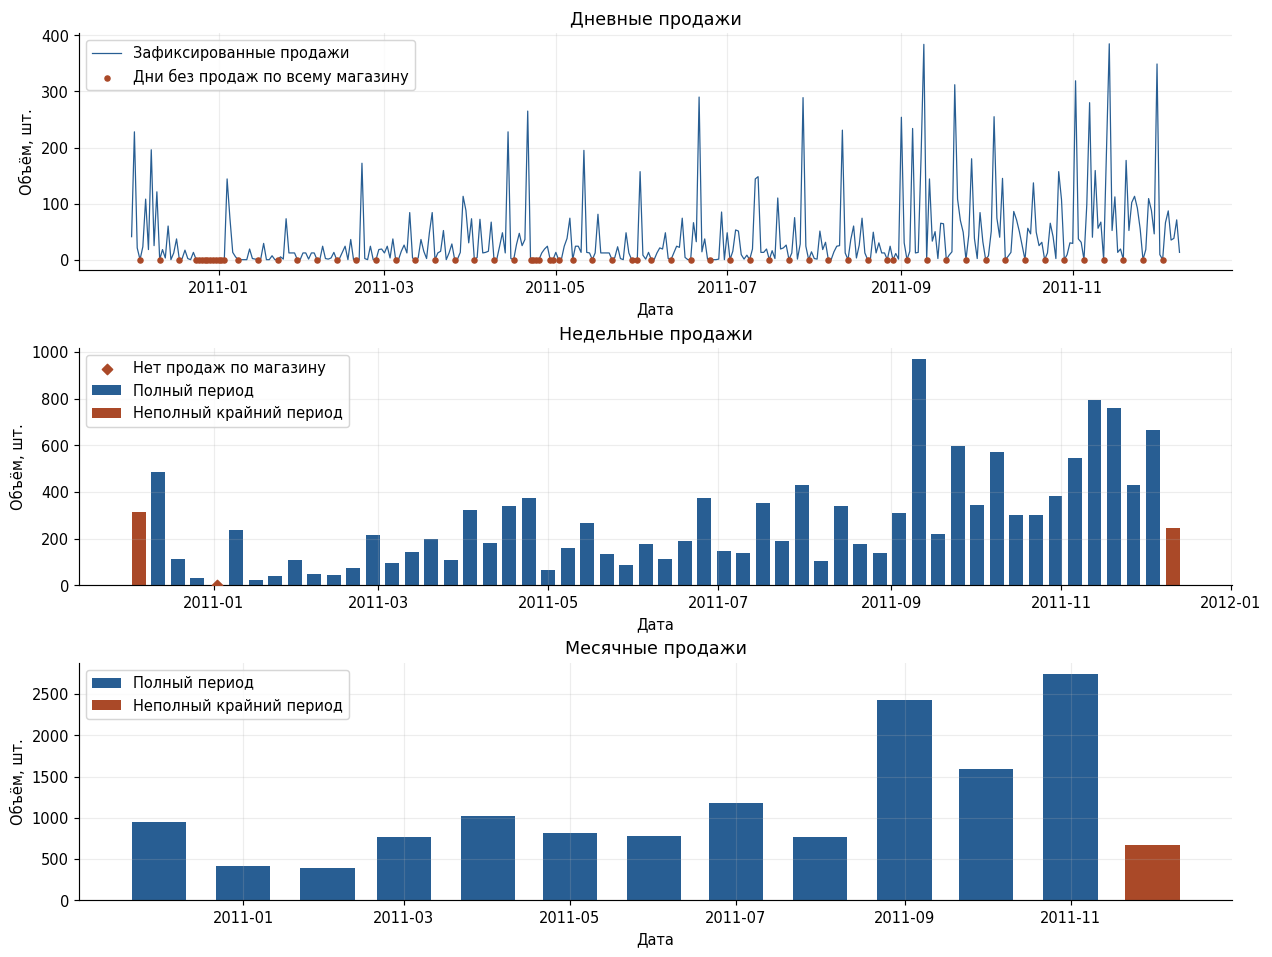

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), layout="constrained")

axes[0].plot(daily.index, daily["units"], color=BLUE, linewidth=0.85, label="Зафиксированные продажи")
unknown = daily.loc[daily["coverage_uncertain"]]
axes[0].scatter(unknown.index, unknown["units"], color=ORANGE, s=12, zorder=4,
                label="Дни без продаж по всему магазину")
axes[0].legend(loc="upper left")

for ax, frame, width in [(axes[1], weekly, 5), (axes[2], monthly, 20)]:
    full = frame["full_period"]
    ax.bar(frame.index[full], frame.loc[full, "units"], width=width, color=BLUE, label="Полный период")
    ax.bar(frame.index[~full], frame.loc[~full, "units"], width=width, color=ORANGE,
           label="Неполный крайний период")
    no_shop_sales = frame["shop_days"].eq(0)
    if no_shop_sales.any():
        ax.scatter(frame.index[no_shop_sales], frame.loc[no_shop_sales, "units"],
                   s=25, color=ORANGE, marker="D", zorder=4, label="Нет продаж по магазину")
    ax.legend(loc="upper left")

for ax, title in zip(axes, ["Дневные продажи", "Недельные продажи", "Месячные продажи"]):
    ax.set(title=title, xlabel="Дата", ylabel="Объём, шт.")
plt.show()

За **374 календарных дня** было продано **14 528 шт.** В дневных суммах 93 нуля: 24 приходятся на дни, когда продавались другие товары, ещё 69 — на дни без продаж по магазину. Все 53 субботы входят в эти 69 дней. Самый длинный разрыв — 11 дней, с 24 декабря 2010 г. по 3 января 2011 г. включительно. Целая неделя с окончанием 2 января попадает в этот разрыв.

Для сравнения всех частот сохраняю исходный календарь. Для STL и проверки стационарности беру непрерывный отрезок из **48 полных недель с 3 января по 4 декабря 2011 г.** У каждой из этих недель есть хотя бы четыре дня с продажами по магазину. Так можно проанализировать уровень на регулярном календаре без целиком пустой недели и без обрезанных недель на краях. Праздничные дни внутри отрезка оставлены с отметками покрытия. Первая и последняя даты исходной выгрузки отражают начало и конец журнала, поэтому внутридневную полноту этих дат подтвердить нельзя.

In [6]:
analysis_weeks = weekly.loc["2011-01-09":"2011-12-04"]
analysis_days = daily.loc["2011-01-03":"2011-12-04"]
y_week = analysis_weeks["units"]
y_day = analysis_days["units"]
assert analysis_weeks["full_period"].all() and analysis_weeks["shop_days"].gt(0).all()
assert len(y_day) == 7 * len(y_week) and y_day.sum() == y_week.sum()

## 3. Высокие значения и изменение разброса

Верхний порог Тьюки `Q3 + 1.5 × (Q3 − Q1)` отмечает необычно высокие суммы. Считаю пороги отдельно: для всего дневного ряда, для 48 недель с сопоставимым покрытием и для полных календарных месяцев. Нижнюю границу здесь не использую: причины нулевых значений уже разобраны по календарю. Порог служит для поиска дат, которые стоит проверить. При росте уровня он может отмечать сразу несколько настоящих пиков к концу года.

,"верхний порог, шт.",отмечено периодов
частота,,
Дни,115.38,32
Недели,702.62,3
Месяцы,2044.88,2


,total,invoices,largest_invoice,largest_share
date,,,,
2011-11-14,385,9,268,0.696
2011-09-09,384,2,360,0.938
2011-12-01,349,12,216,0.619
2011-11-02,319,5,288,0.903
2011-09-20,312,3,288,0.923
2011-06-21,290,3,288,0.993
2011-07-28,289,2,288,0.997
2011-11-07,280,3,253,0.904
2011-04-21,265,3,216,0.815


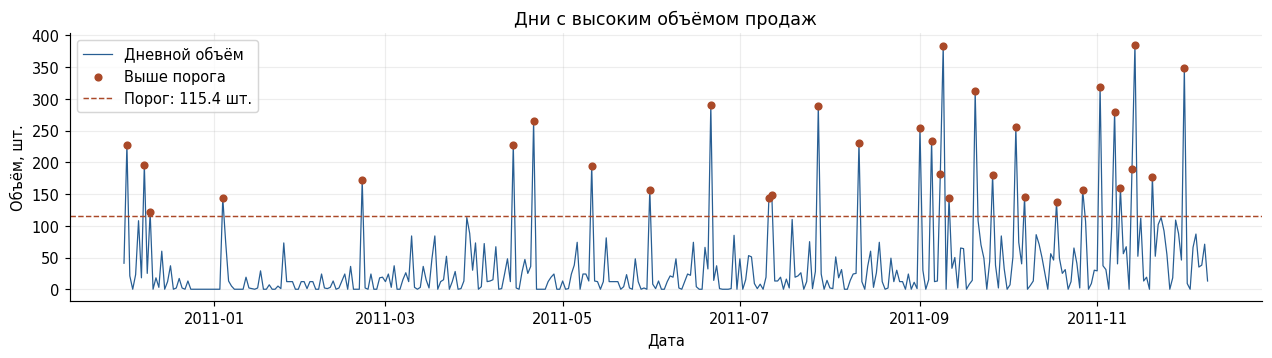

In [7]:
samples = {
    "Дни": daily["units"],
    "Недели": y_week,
    "Месяцы": monthly.loc[monthly["full_period"], "units"],
}
outliers = {label: upper_iqr_flags(values) for label, values in samples.items()}
display(
    pd.DataFrame(
        [(label, limit, int(mask.sum())) for label, (mask, limit) in outliers.items()],
        columns=["частота", "верхний порог, шт.", "отмечено периодов"],
    ).set_index("частота").round(2)
)

flagged, limit = outliers["Дни"]
peaks = daily.loc[flagged, "units"].sort_values(ascending=False)
display(peak_invoice_summary(product, peaks.index).sort_values("total", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(12, 3.3), layout="constrained")
ax.plot(daily.index, daily["units"], color=BLUE, linewidth=0.85, label="Дневной объём")
ax.scatter(peaks.index, peaks, color=ORANGE, s=21, zorder=3, label="Выше порога")
ax.axhline(limit, color=ORANGE, linestyle="--", linewidth=1, label=f"Порог: {limit:.1f} шт.")
ax.set(title="Дни с высоким объёмом продаж", xlabel="Дата", ylabel="Объём, шт.")
ax.legend(loc="upper left")
plt.show()

Из 374 дней порог отмечает 32. Например, 9 сентября продано 384 шт., из них 360 в одном счёте. У самого высокого пика, 14 ноября, 385 шт. распределены по девяти счетам. Большие объёмы видны в исходных счетах, и по этим записям оснований исправлять их нет. Я оставляю пики в ряду. Нулевая неделя с неизвестным покрытием также остаётся на обзорном графике. Пропуски интерполяцией не заполняю.

,Дни,Недели,Месяцы
периодов,374.00,48.00,12.00
сумма,14528.00,13339.00,13860.00
среднее,38.84,277.90,1155.00
медиана,13.00,206.50,882.50
σ,65.11,213.61,740.39
CV,1.68,0.77,0.64
P95,180.35,726.15,2564.65
пик,385.00,968.00,2739.00
"нулевых, %",24.87,0.00,0.00


,недель,среднее,медиана,σ
date,,,,
2011Q1,12,111.4,101.5,72.3
2011Q2,13,214.6,180.0,108.5
2011Q3,13,317.2,222.0,241.3
2011Q4,10,508.9,488.0,185.3


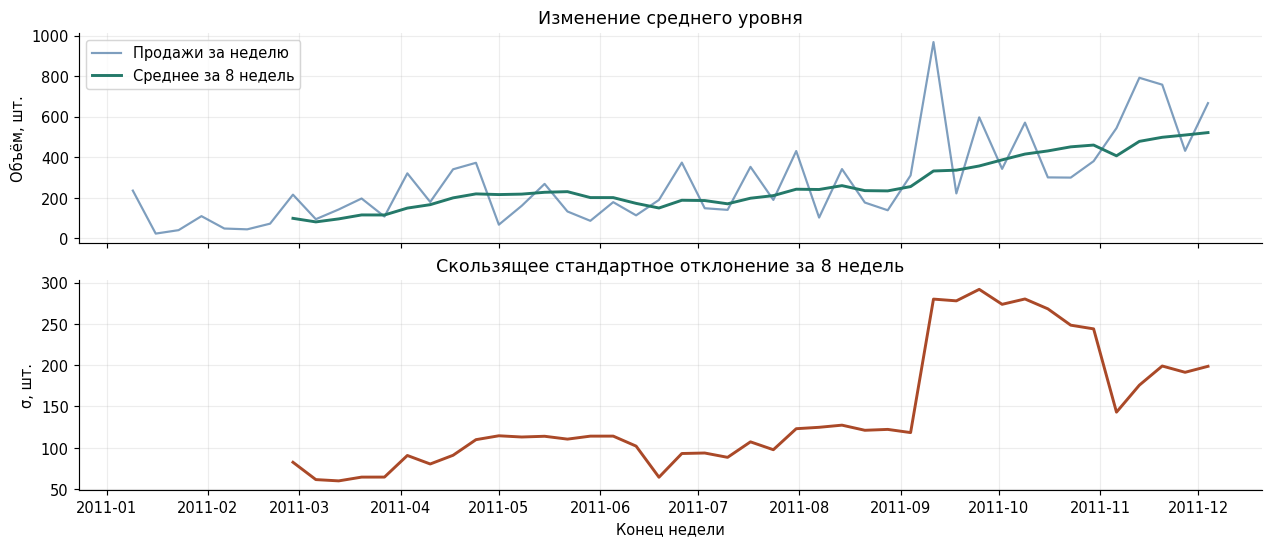

In [8]:
display(pd.DataFrame({label: describe_sales(y) for label, y in samples.items()}).round(2))
quarter_summary = y_week.groupby(y_week.index.to_period("Q")).agg(["size", "mean", "median", "std"])
display(quarter_summary.rename(columns={
    "size": "недель", "mean": "среднее", "median": "медиана", "std": "σ"
}).round(1))

rolling = y_week.rolling(8, min_periods=8)
fig, axes = plt.subplots(2, 1, figsize=(12, 5.1), sharex=True, layout="constrained")
axes[0].plot(y_week.index, y_week, color=BLUE, alpha=0.6, label="Продажи за неделю")
axes[0].plot(y_week.index, rolling.mean(), color=GREEN, linewidth=2, label="Среднее за 8 недель")
axes[0].set(title="Изменение среднего уровня", ylabel="Объём, шт.")
axes[0].legend(loc="upper left")
axes[1].plot(y_week.index, rolling.std(), color=ORANGE, linewidth=2)
axes[1].set(title="Скользящее стандартное отклонение за 8 недель", xlabel="Конец недели", ylabel="σ, шт.")
plt.show()

Средний день даёт 38,8 шт. при медиане 13 шт. Разницу создают крупные партии и дни с нулевым объёмом. Относительный разброс (CV) падает с 1,68 на дневной частоте до 0,77 на недельной и 0,64 на месячной. Эти оценки получены на доступных интервалах каждой частоты. Недельные суммы сглаживают разброс, связанный с днём недели, и оставляют достаточно периодов для диагностики. Полных месяцев всего 12.

Недельная медиана выросла с **101,5 шт. в I квартале до 488 шт. на доступном отрезке IV квартала**. Разброс заметно увеличивается к концу лета и осенью, в том числе из-за недели с пиком 968 шт. Это аргумент против постоянного уровня и постоянной дисперсии на всей выборке. По одному году нельзя отделить рост продаж от возможного эффекта календаря.

## 4. Декомпозиция и сезонность

Недельный рисунок лучше проверять по дням. Для дневных объёмов использую аддитивную робастную декомпозицию **STL с периодом 7**. Все компоненты измеряются в штуках. Робастная подгонка ограничивает влияние пиков на оценку тренда и сезонной компоненты, сохраняя наблюдения в исходном ряду. Дополнительно смотрю ACF на лагах 7, 14 и 21 и профиль дней недели. Профиль только по дням с продажами магазина помогает понять, какая часть рисунка связана с календарём работы.

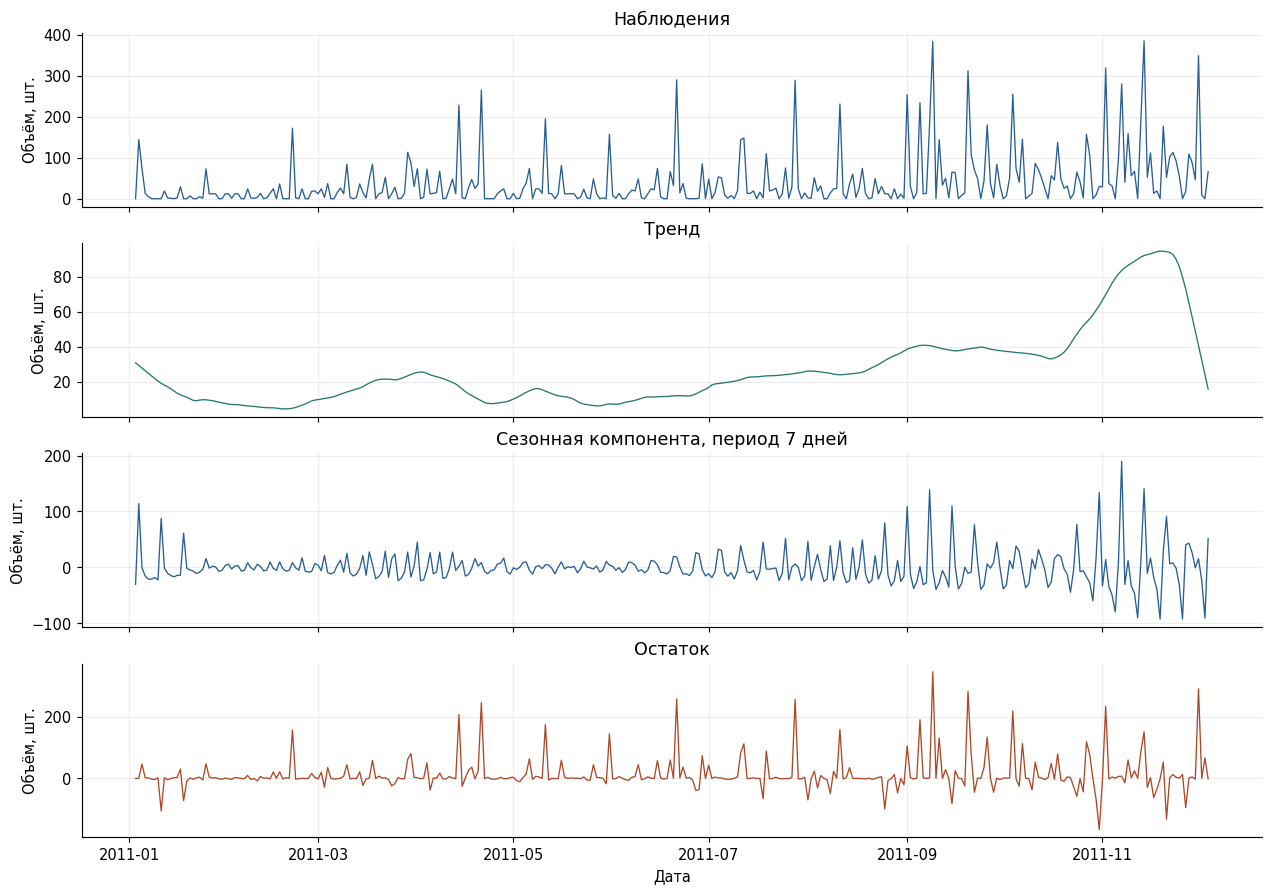

Сила сезонной компоненты STL: 0.177


,"медиана тренда, шт./день"
date,
2011Q1,11.0
2011Q2,11.6
2011Q3,26.0
2011Q4,55.9


In [9]:
stl, strength = decompose(y_day, period=7)
components = [
    ("Наблюдения", y_day, BLUE),
    ("Тренд", stl.trend, GREEN),
    ("Сезонная компонента, период 7 дней", stl.seasonal, BLUE),
    ("Остаток", stl.resid, ORANGE),
]
fig, axes = plt.subplots(4, 1, figsize=(12, 8.4), sharex=True, layout="constrained")
for ax, (title, values, color) in zip(axes, components):
    ax.plot(values.index, values, color=color, linewidth=0.9)
    ax.set(title=title, ylabel="Объём, шт.")
axes[-1].set_xlabel("Дата")
plt.show()

print(f"Сила сезонной компоненты STL: {strength:.3f}")
display(
    stl.trend.groupby(stl.trend.index.to_period("Q")).median().round(1)
    .to_frame("медиана тренда, шт./день")
)

,дневной ряд,остаток STL,первая половина,вторая половина
лаг,,,,
7,0.225,-0.013,0.218,0.164
14,0.181,-0.022,0.036,0.147
21,0.206,0.098,0.086,0.143


,дней,дней с продажами магазина,среднее по календарю,среднее в дни продаж магазина,медиана в дни продаж магазина
день,,,,,
Пн,48,43,53.7,60.0,30.0
Вт,48,48,56.1,56.1,24.5
Ср,48,48,42.0,42.0,19.0
Чт,48,48,65.6,65.6,33.0
Пт,48,46,35.5,37.0,19.0
Сб,48,0,0.0,NaN,NaN
Вс,48,47,24.9,25.4,12.0


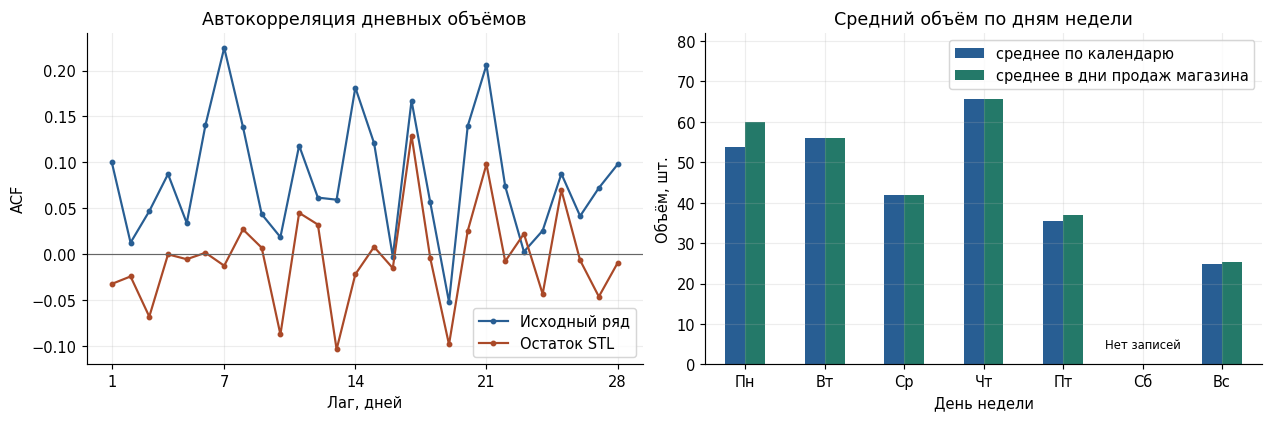

In [10]:
acf_day = autocorrelations(y_day)
acf_resid = autocorrelations(stl.resid)
first_half = y_day.iloc[:len(y_day) // 2]
second_half = y_day.iloc[len(y_day) // 2:]
display(
    pd.DataFrame({
        "дневной ряд": acf_day,
        "остаток STL": acf_resid,
        "первая половина": autocorrelations(first_half),
        "вторая половина": autocorrelations(second_half),
    }).loc[[7, 14, 21]].round(3)
)

profile = weekday_profile(analysis_days).rename(columns={
    "days": "дней",
    "shop_days": "дней с продажами магазина",
    "calendar_mean": "среднее по календарю",
    "active_mean": "среднее в дни продаж магазина",
    "active_median": "медиана в дни продаж магазина",
})
display(profile.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), layout="constrained")
acf_table = pd.DataFrame({"Исходный ряд": acf_day, "Остаток STL": acf_resid})
axes[0].plot(acf_table.index[1:], acf_table["Исходный ряд"].iloc[1:], marker="o", ms=3,
             color=BLUE, label="Исходный ряд")
axes[0].plot(acf_table.index[1:], acf_table["Остаток STL"].iloc[1:], marker="o", ms=3,
             color=ORANGE, label="Остаток STL")
axes[0].axhline(0, color="0.4", linewidth=0.8)
axes[0].set(title="Автокорреляция дневных объёмов", xlabel="Лаг, дней", ylabel="ACF", xticks=[1, 7, 14, 21, 28])
axes[0].legend()

profile[["среднее по календарю", "среднее в дни продаж магазина"]].plot.bar(
    ax=axes[1], color=[BLUE, GREEN], rot=0,
)
axes[1].set(title="Средний объём по дням недели", xlabel="День недели", ylabel="Объём, шт.")
axes[1].set_ylim(0, profile["среднее в дни продаж магазина"].max() * 1.25)
axes[1].text(5, 4, "Нет записей", ha="center", fontsize=8)
plt.show()

**Тренд.** Медиана сглаженного уровня поднимается примерно с 11 шт. в день в I квартале до 56 в доступной части IV квартала. Это согласуется с ростом недельных медиан. На правом краю тренд STL резко падает. У оценки на границе меньше соседних наблюдений, поэтому оснований говорить о развороте по этому участку мало.

**Сезонная компонента.** В календарных продажах есть умеренный рисунок с периодом 7 дней. ACF исходного ряда на лагах 7, 14 и 21 составляет 0,225, 0,181 и 0,206. На лаге 7 связь видна в обеих половинах отрезка (0,218 и 0,164). На субботу приходится регулярный нулевой вклад магазина. Даже среди дней с продажами медиана в четверг выше воскресной (33 против 12 шт.). Мера силы сезонной компоненты `max(0, 1 − Var(остаток) / Var(сезонная компонента + остаток))` равна 0,177. Следовательно, недельный ритм различим, но помимо него остаётся заметная изменчивость. О причинах различий спроса по дням недели из журнала судить нельзя.

**Остаток.** После STL автокорреляции на лагах 7 и 14 близки к нулю (−0,013 и −0,022). При этом в остатке есть большие скачки, например в дни крупных заказов. Это аргумент против использования одного календарного профиля как полноценного описания продаж. Для вывода о годовой сезонности одного годового цикла недостаточно.

## 5. Стационарность недельных продаж

Для недельного объёма проверяю стационарность вокруг постоянного уровня при уровне значимости 5%.

- **ADF:** нулевая гипотеза — есть единичный корень. Число лагов выбирается по AIC.
- **KPSS:** нулевая гипотеза — стационарность вокруг постоянного уровня. Число лагов выбирается автоматически. Знаки `<` и `>` в таблице означают, что p-значение выходит за пределы таблицы критических значений теста.

Абсолютный разброс больше на высоких уровнях, поэтому пробую `log1p(y)` для сжатия больших значений. Затем сравниваю первые разности исходного и логарифмированного рядов. Для сравнения масштаба внутри каждого ряда делю его наблюдения пополам по времени и считаю стандартные отклонения.

In [11]:
log_week = np.log1p(y_week)
variants = {
    "Недельный объём": y_week,
    "log1p объёма": log_week,
    "Первая разность объёма": y_week.diff().dropna(),
    "Первая разность log1p": log_week.diff().dropna(),
}
test_results = pd.concat(
    {label: stationarity_tests(values) for label, values in variants.items()},
    names=["ряд", "тест"],
)
display(test_results.round(3))

def variability_comparison(series):
    midpoint = len(series) // 2
    return pd.Series({
        "σ первой половины": series.iloc[:midpoint].std(),
        "σ второй половины": series.iloc[midpoint:].std(),
        "ACF на лаге 1": autocorrelations(series, nlags=1).loc[1],
    })

display(pd.DataFrame({label: variability_comparison(values) for label, values in variants.items()}).T.round(3))

статистика         p  лаги  H₀ отклонена при 5%
ряд                    тест                                                 
Недельный объём        ADF       -2.029    0.2741     1                False
                       KPSS       0.851    < 0.01     4                 True
log1p объёма           ADF       -1.767    0.3972     2                False
                       KPSS       0.864    < 0.01     4                 True
Первая разность объёма ADF       -6.353  2.59e-08     2                 True
                       KPSS       0.190    > 0.10     8                False
Первая разность log1p  ADF       -6.677  4.44e-09     2                 True
                       KPSS       0.323    > 0.10    21                False

,σ первой половины,σ второй половины,ACF на лаге 1
Недельный объём,97.732,229.935,0.414
log1p объёма,0.711,0.606,0.489
Первая разность объёма,125.637,295.112,-0.569
Первая разность log1p,0.879,0.778,-0.461


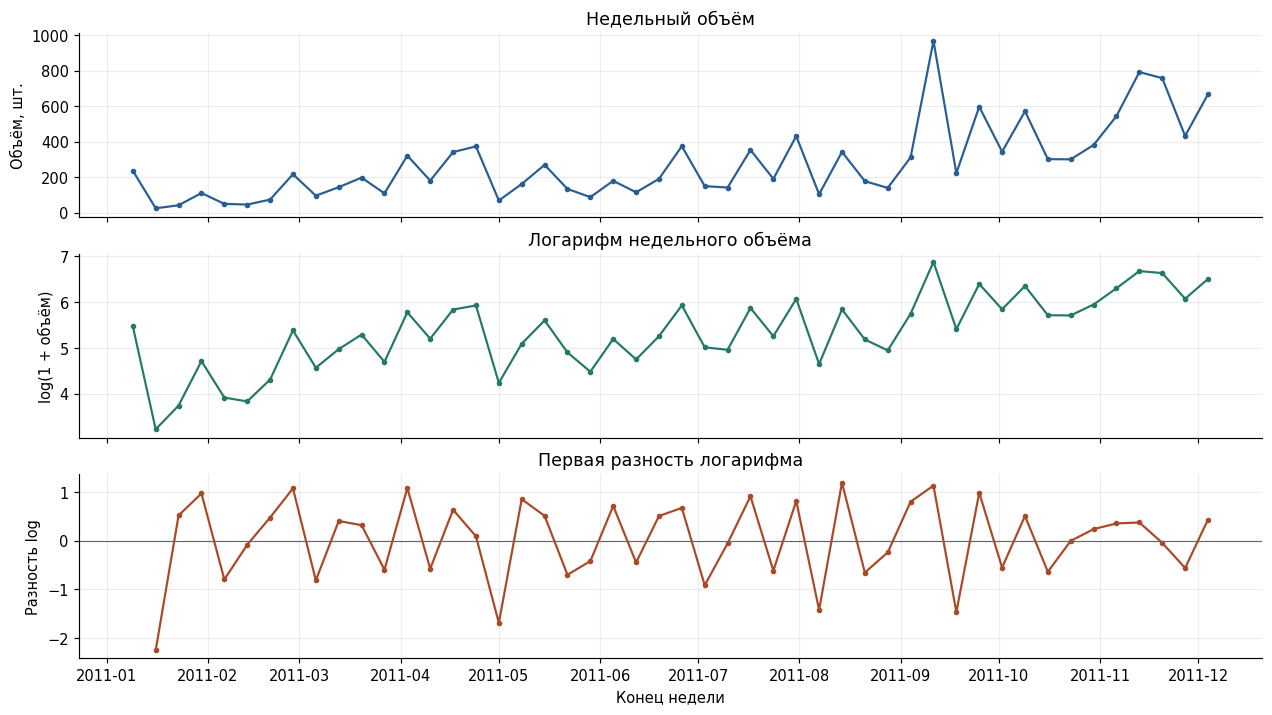

статистика          p  лаги  \
ряд          тест с линейным трендом                                
объём        ADF                          -7.105  8.178e-09     0   
             KPSS                          0.146     = 0.05     2   
log1p объёма ADF                          -7.566  7.182e-10     0   
             KPSS                          0.080     > 0.10     2   

                                      H₀ отклонена при 5%  
ряд          тест с линейным трендом                       
объём        ADF                                     True  
             KPSS                                    True  
log1p объёма ADF                                     True  
             KPSS                                   False

In [12]:
transformed = variants["Первая разность log1p"]
fig, axes = plt.subplots(3, 1, figsize=(12, 6.7), sharex=True, layout="constrained")
for ax, (title, values, color, unit) in zip(axes, [
    ("Недельный объём", y_week, BLUE, "Объём, шт."),
    ("Логарифм недельного объёма", log_week, GREEN, "log(1 + объём)"),
    ("Первая разность логарифма", transformed, ORANGE, "Разность log"),
]):
    ax.plot(values.index, values, color=color, marker="o", markersize=2.8)
    ax.set(title=title, ylabel=unit)
axes[2].axhline(0, color="0.4", linewidth=0.8)
axes[2].set_xlabel("Конец недели")
plt.show()

display(
    pd.concat(
        {"объём": stationarity_tests(y_week, regression="ct"),
         "log1p объёма": stationarity_tests(log_week, regression="ct")},
        names=["ряд", "тест с линейным трендом"],
    ).round(3)
)

Для исходных недельных сумм ADF даёт **p = 0,2741**, а KPSS — **p < 0,01**. Нулевая гипотеза ADF не отклоняется, а KPSS отклоняет стационарность вокруг постоянного уровня. Само логарифмирование уменьшает разницу в разбросе, но не убирает изменение уровня. После первой разности `log1p` ADF даёт **p ≈ 4,44 × 10⁻⁹**, KPSS — **p > 0,10**. Это согласуется со стационарностью преобразованного ряда в пределах имеющейся выборки. В сравнении с разностями в штуках разброс двух половин ближе (0,879 и 0,778), поэтому для модели, требующей ряда с постоянным уровнем, я бы начал с `Δ log(1 + y)`.

Проверка с линейным трендом уточняет картину. Для `log1p` ADF с трендом отклоняет единичный корень, а KPSS не отклоняет стационарность вокруг тренда. Модель с явным трендом на логарифмической шкале тоже имеет смысл проверить. ACF разностей `log1p` на первом лаге около −0,46. Это повод сравнить подходы на отложенных неделях, прежде чем выбирать порядок дифференцирования.

## 6. Итог

Для прогноза объёма на неделю вперёд я бы использовал недельную частоту. Она сглаживает различия между днями недели и сохраняет достаточно наблюдений для первичной оценки. В журнале есть крупные продажи, связанные с отдельными счетами. Их стоит учитывать при оценке ошибок, особенно в периоды с высоким уровнем продаж. Дни без записей по всему магазину остаются помеченными, а целиком пустая неделя и неполные края лежат за пределами отрезка, использованного для тестов.

Исходный недельный ряд заметно меняется по уровню, а первая разность логарифма согласуется со стационарностью по ADF и KPSS. При переходе к прогнозированию я бы сравнил её с моделью тренда и простым прогнозом по последней неделе. Проверку имеет смысл вести по времени, вычисляя параметры только на доступной к моменту прогноза истории. Периода выгрузки недостаточно для оценки повторяющегося годового эффекта.